# Handwritten Digit Recognition using CNN

## 1. Import Libraries

In this section, we import the libraries needed to load,
process, visualize and train our CNN model.

In [11]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.22.0-rc0
NumPy version: 2.5.4


## 2. Load the MNIST Dataset

We use the MNIST dataset provided by Keras.
It contains handwritten digit images and their corresponding labels.

In [12]:
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Dataset loaded successfully!")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 8s 1us/step
Dataset loaded successfully!


## 3. Explore the Dataset

We inspect the dimensions of the training and testing data
to understand how the images are represented.

In [13]:
print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing images shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)


## 4. Visualize the Dataset

We display some training images and their corresponding labels
to understand what the model will learn to recognize.

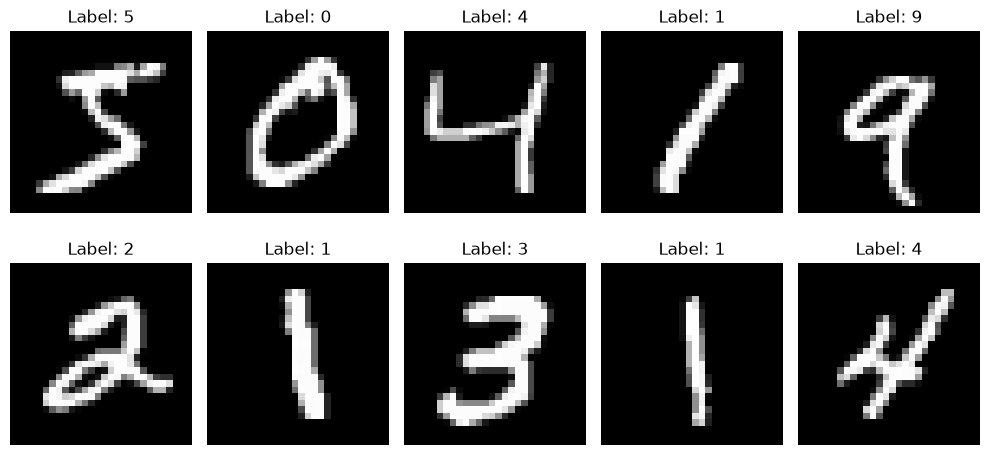

In [14]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

## 5. Data Preprocessing

### 5.1 Normalization

We normalize pixel values from 0-255 to 0-1
to make training more efficient and stable.

In [15]:
# Normalize pixel values
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


### 5.2 Reshaping

CNNs expect image data to have four dimensions:

(samples, height, width, channels).

Since MNIST contains grayscale images, we add one channel.

In [16]:
# Reshape training and testing images
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


In [17]:
print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

print("Pixel minimum:", x_train.min())
print("Pixel maximum:", x_train.max())

Training images: (60000, 28, 28, 1)
Testing images: (10000, 28, 28, 1)
Pixel minimum: 0.0
Pixel maximum: 1.0


## 6. Building the CNN Model

We create a Convolutional Neural Network using Keras.

The architecture contains:
- Two convolutional layers.
- Two max pooling layers.
- One flatten layer.
- One dense layer.
- One dropout layer.
- One output layer.

In [18]:
# Import required layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

# Create the CNN model
model = Sequential([

    # First convolutional layer
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(28, 28, 1)),

    # First pooling layer
    MaxPooling2D(pool_size=(2, 2)),

    # Second convolutional layer
    Conv2D(64, (3, 3), activation='relu'),

    # Second pooling layer
    MaxPooling2D(pool_size=(2, 2)),

    # Convert feature maps into a vector
    Flatten(),

    # Fully connected layer
    Dense(128, activation='relu'),

    # Prevent overfitting
    Dropout(0.3),

    # Output layer: 10 digit classes
    Dense(10, activation='softmax')
])

/home/baya/Documents/cnn_mnist/.venv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1794594014.945073  292286 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [19]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Compile the CNN Model

We configure the model using:
- Adam optimizer.
- Sparse Categorical Crossentropy loss.
- Accuracy metric.

In [20]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## 8. Train the CNN Model

We train our CNN using the training dataset.

We use:
- 5 epochs.
- Batch size of 64.
- 10% of training data for validation.

In [21]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5


W0000 00:00:1794594154.273695  292286 cpu_allocator_impl.cc:174] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.9355 - loss: 0.2097 - val_accuracy: 0.9860 - val_loss: 0.0515
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.9799 - loss: 0.0669 - val_accuracy: 0.9892 - val_loss: 0.0438
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9852 - loss: 0.0482 - val_accuracy: 0.9898 - val_loss: 0.0415
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9880 - loss: 0.0389 - val_accuracy: 0.9870 - val_loss: 0.0480
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.9901 - loss: 0.0302 - val_accuracy: 0.9895 - val_loss: 0.0397


### Training and Validation Performance

We visualize accuracy and loss across the five epochs
to understand how the model improved during training.

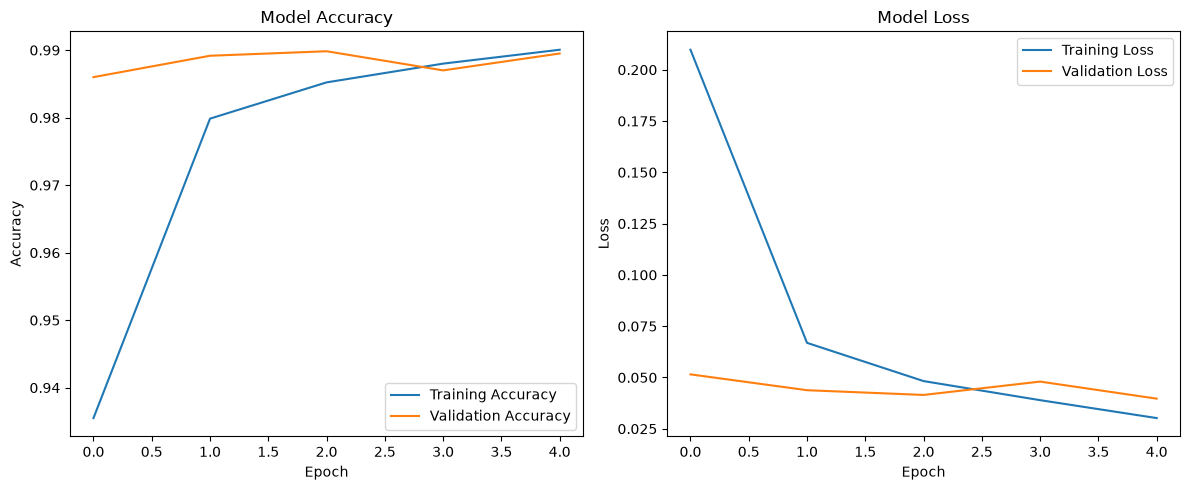

In [22]:
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

## 9. Model Evaluation

We evaluate our trained CNN using the testing dataset
to measure its performance on unseen images.

In [23]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9901 - loss: 0.0303
Test Loss: 0.030331073328852654
Test Accuracy: 99.01000261306763 %


## 10. Making Predictions

We use our trained CNN to predict handwritten digits
from the testing dataset.

In [24]:
# Generate predictions
predictions = model.predict(x_test)

print("Predictions shape:", predictions.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Predictions shape: (10000, 10)


In [25]:
# Get the class with the highest probability
predicted_labels = np.argmax(predictions, axis=1)

print("Predicted digit:", predicted_labels[0])
print("Actual digit:", y_test[0])

Predicted digit: 7
Actual digit: 7


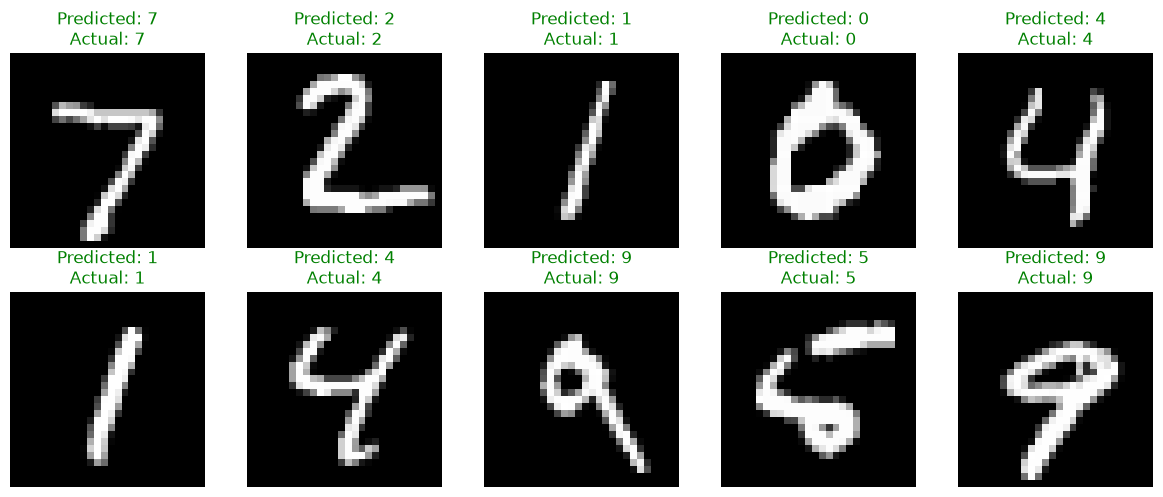

In [26]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    predicted = predicted_labels[i]
    actual = y_test[i]

    color = 'green' if predicted == actual else 'red'

    plt.title(
        f"Predicted: {predicted}\nActual: {actual}",
        color=color
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

## 11. Testing with a Custom Image

We test our trained CNN using a handwritten digit
that was not included in the MNIST dataset.

In [ ]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

# Load our image
img = Image.open('../my_digit.png').convert('L')

# Display original image
plt.imshow(img, cmap='gray')
plt.title("My Handwritten Digit")
plt.axis('off')
plt.show()

In [ ]:
# Improve image contrast
img = ImageOps.autocontrast(img)

# Invert colors: black digit on white paper
img = ImageOps.invert(img)

# Remove background noise using a threshold
img = img.point(lambda p: 255 if p > 80 else 0)

# Crop around the digit
bbox = img.getbbox()
img = img.crop(bbox)

# Resize while maintaining proportions
img.thumbnail((20, 20))

# Create a 28x28 black canvas
new_img = Image.new('L', (28, 28), 0)

# Center the digit
x = (28 - img.width) // 2
y = (28 - img.height) // 2

new_img.paste(img, (x, y))

# Display processed image
plt.imshow(new_img, cmap='gray')
plt.title("Processed Image")
plt.axis('off')
plt.show()

In [ ]:
# Convert image into a NumPy array
img_array = np.array(new_img)

# Normalize pixel values
img_array = img_array.astype('float32') / 255.0

# Add batch and channel dimensions
img_array = img_array.reshape(1, 28, 28, 1)

# Predict
prediction = model.predict(img_array)

# Get predicted digit
predicted_digit = np.argmax(prediction)

# Get confidence
confidence = np.max(prediction) * 100

print("Predicted digit:", predicted_digit)
print("Confidence:", round(confidence, 2), "%")

In [27]:
model.save('../models/mnist_cnn.keras')

print("Model saved successfully!")

Model saved successfully!
